# HR Attrition: Initial EDA

Use this notebook to load the IBM HR Analytics Employee Attrition dataset, inspect data quality, and produce the EDA figures saved to `docs/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
DATA_PATH = "../data/raw/hrattrition.csv"
df = pd.read_csv(DATA_PATH)

print(f"Shape: {df.shape}")
display(df.head())
display(df.dtypes)

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
Over18                        str
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StandardHours               int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesL

## Data Quality Notes

Record missing values, target imbalance, unusual ranges, and anything that may affect preprocessing decisions in the preprocessing stage (`src/preprocess.py`).

In [3]:
display(df.describe())
print("Missing values per column:")
display(df.isnull().sum())
print("Target distribution:")
display(df["Attrition"].value_counts())
display(df["Attrition"].value_counts(normalize=True).round(3))

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


Missing values per column:


Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

Target distribution:


Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition
No     0.839
Yes    0.161
Name: proportion, dtype: float64

## Target Distribution

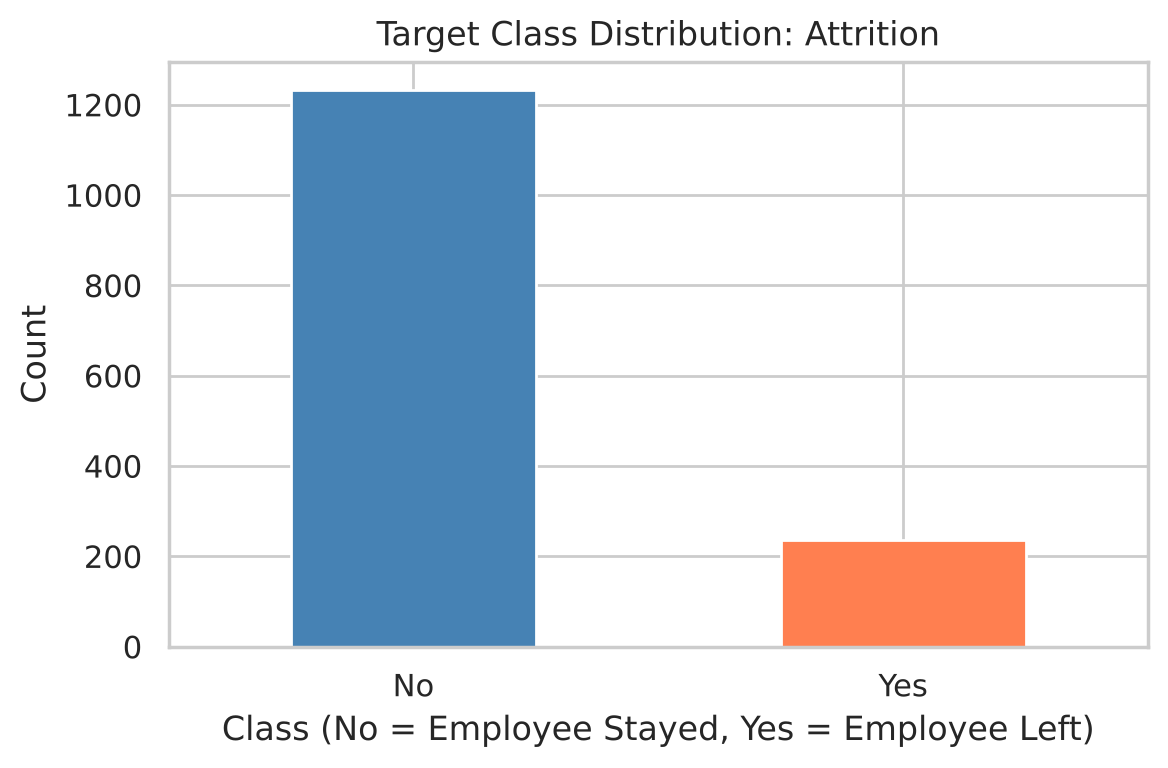

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
df["Attrition"].value_counts().plot(kind="bar", ax=ax, color=["steelblue", "coral"])
ax.set_title("Target Class Distribution: Attrition")
ax.set_xlabel("Class (No = Employee Stayed, Yes = Employee Left)")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../docs/eda_target_distribution.png", dpi=150)
plt.show()

## Age and Income Distributions

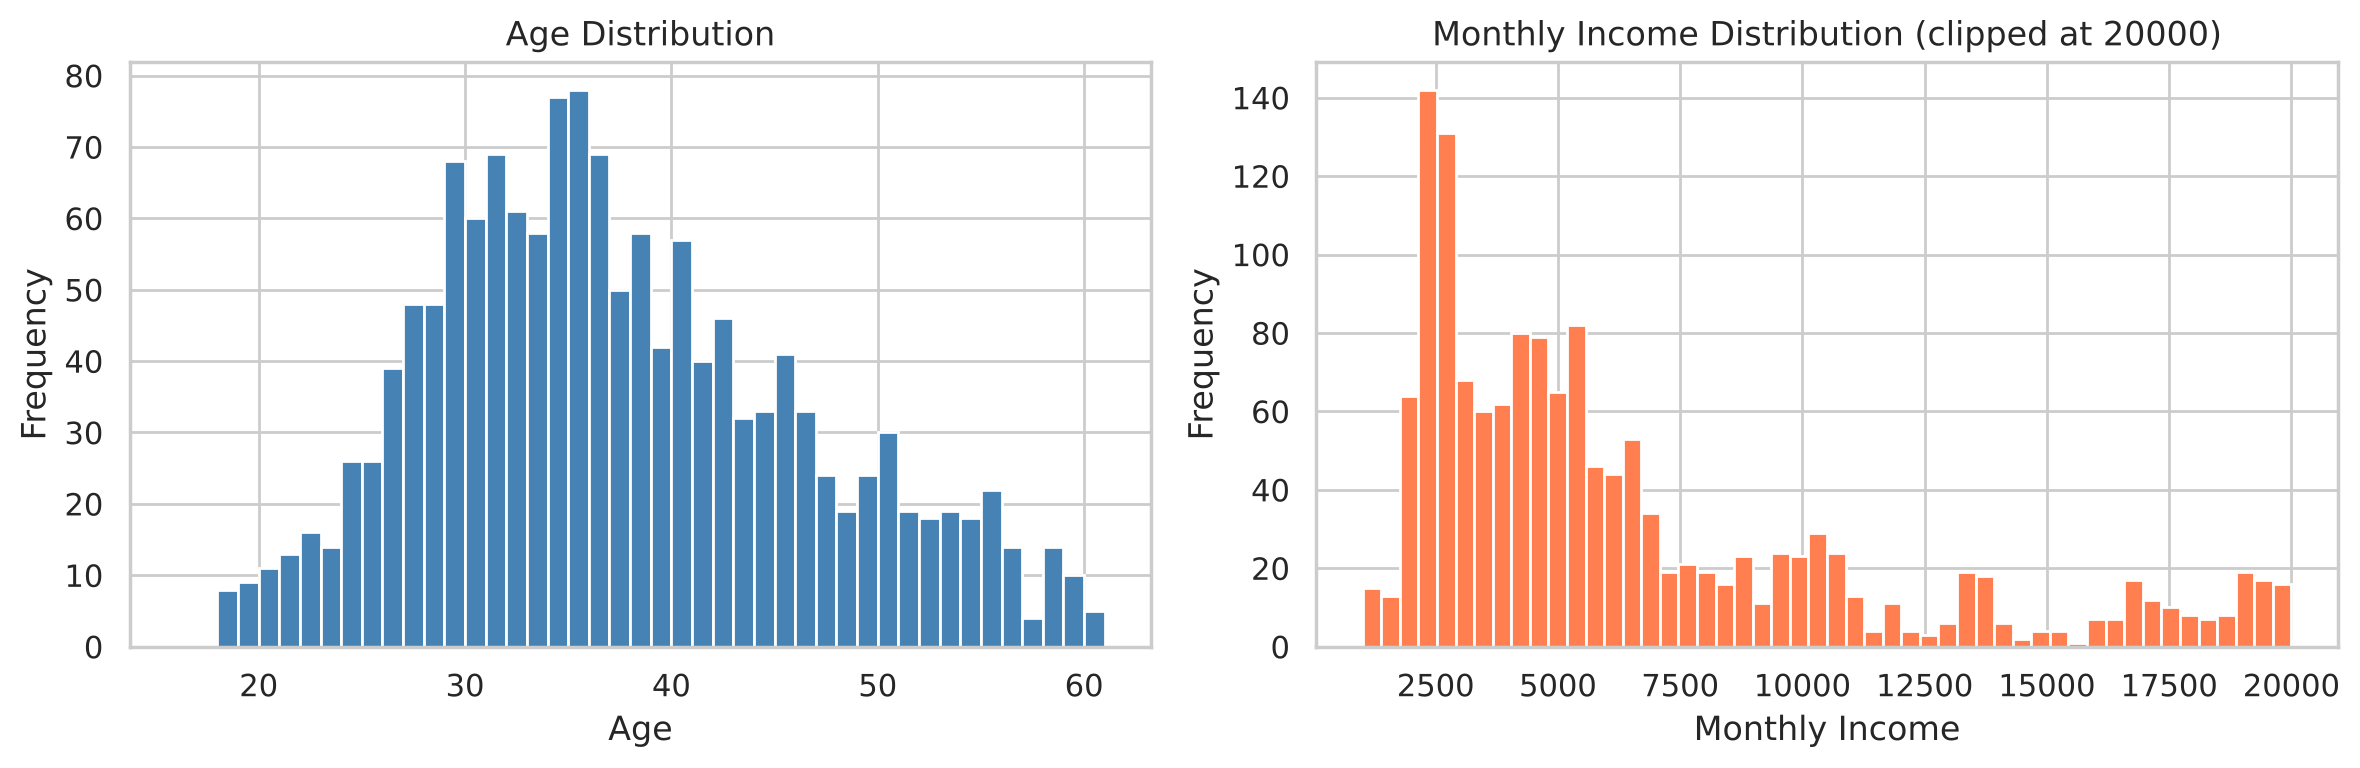

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Age"].plot(kind="hist", bins=range(16, 62), ax=axes[0], color="steelblue", edgecolor="white")
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")

df["MonthlyIncome"].clip(upper=20000).plot(kind="hist", bins=50, ax=axes[1], color="coral", edgecolor="white")
axes[1].set_title("Monthly Income Distribution (clipped at 20000)")
axes[1].set_xlabel("Monthly Income")

plt.tight_layout()
plt.savefig("../docs/eda_age_income.png", dpi=150)
plt.show()

## Ratio Features

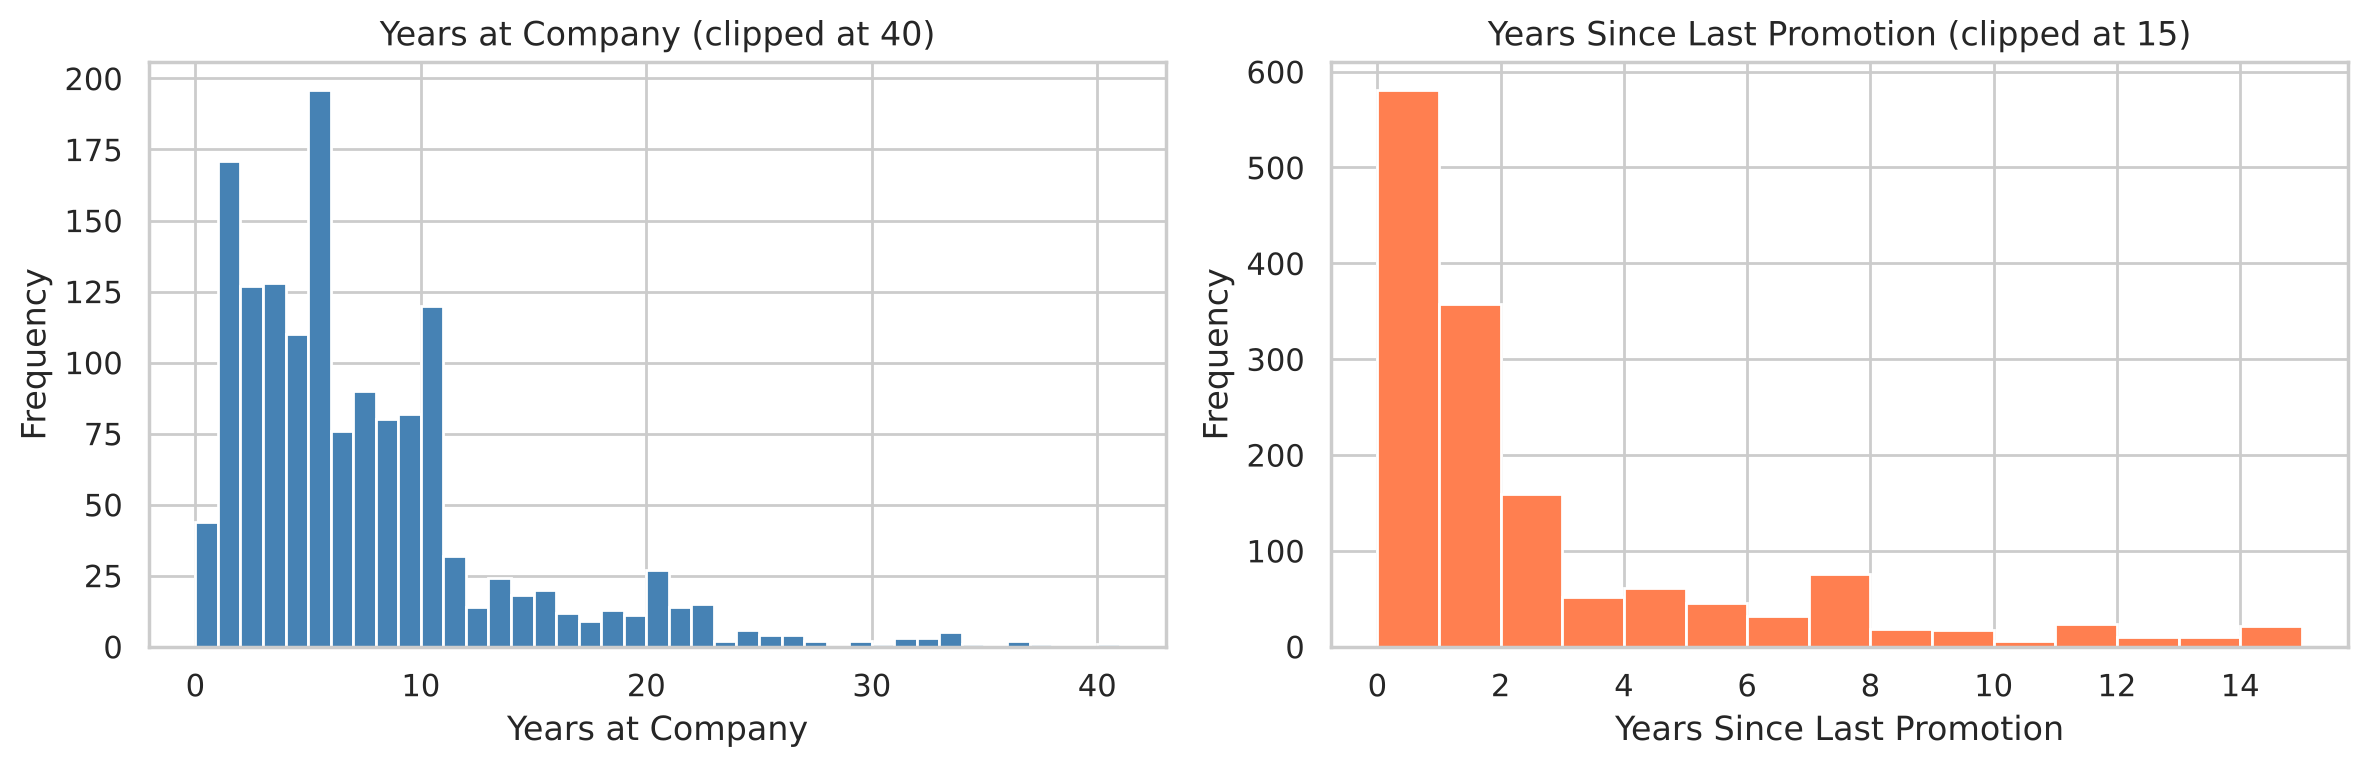

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["YearsAtCompany"].clip(upper=40).plot(kind="hist", bins=range(0, 42), ax=axes[0], color="steelblue", edgecolor="white")
axes[0].set_title("Years at Company (clipped at 40)")
axes[0].set_xlabel("Years at Company")

df["YearsSinceLastPromotion"].clip(upper=15).plot(kind="hist", bins=range(0, 16), ax=axes[1], color="coral", edgecolor="white")
axes[1].set_title("Years Since Last Promotion (clipped at 15)")
axes[1].set_xlabel("Years Since Last Promotion")

plt.tight_layout()
plt.savefig("../docs/eda_ratios.png", dpi=150)
plt.show()

## Correlation Overview

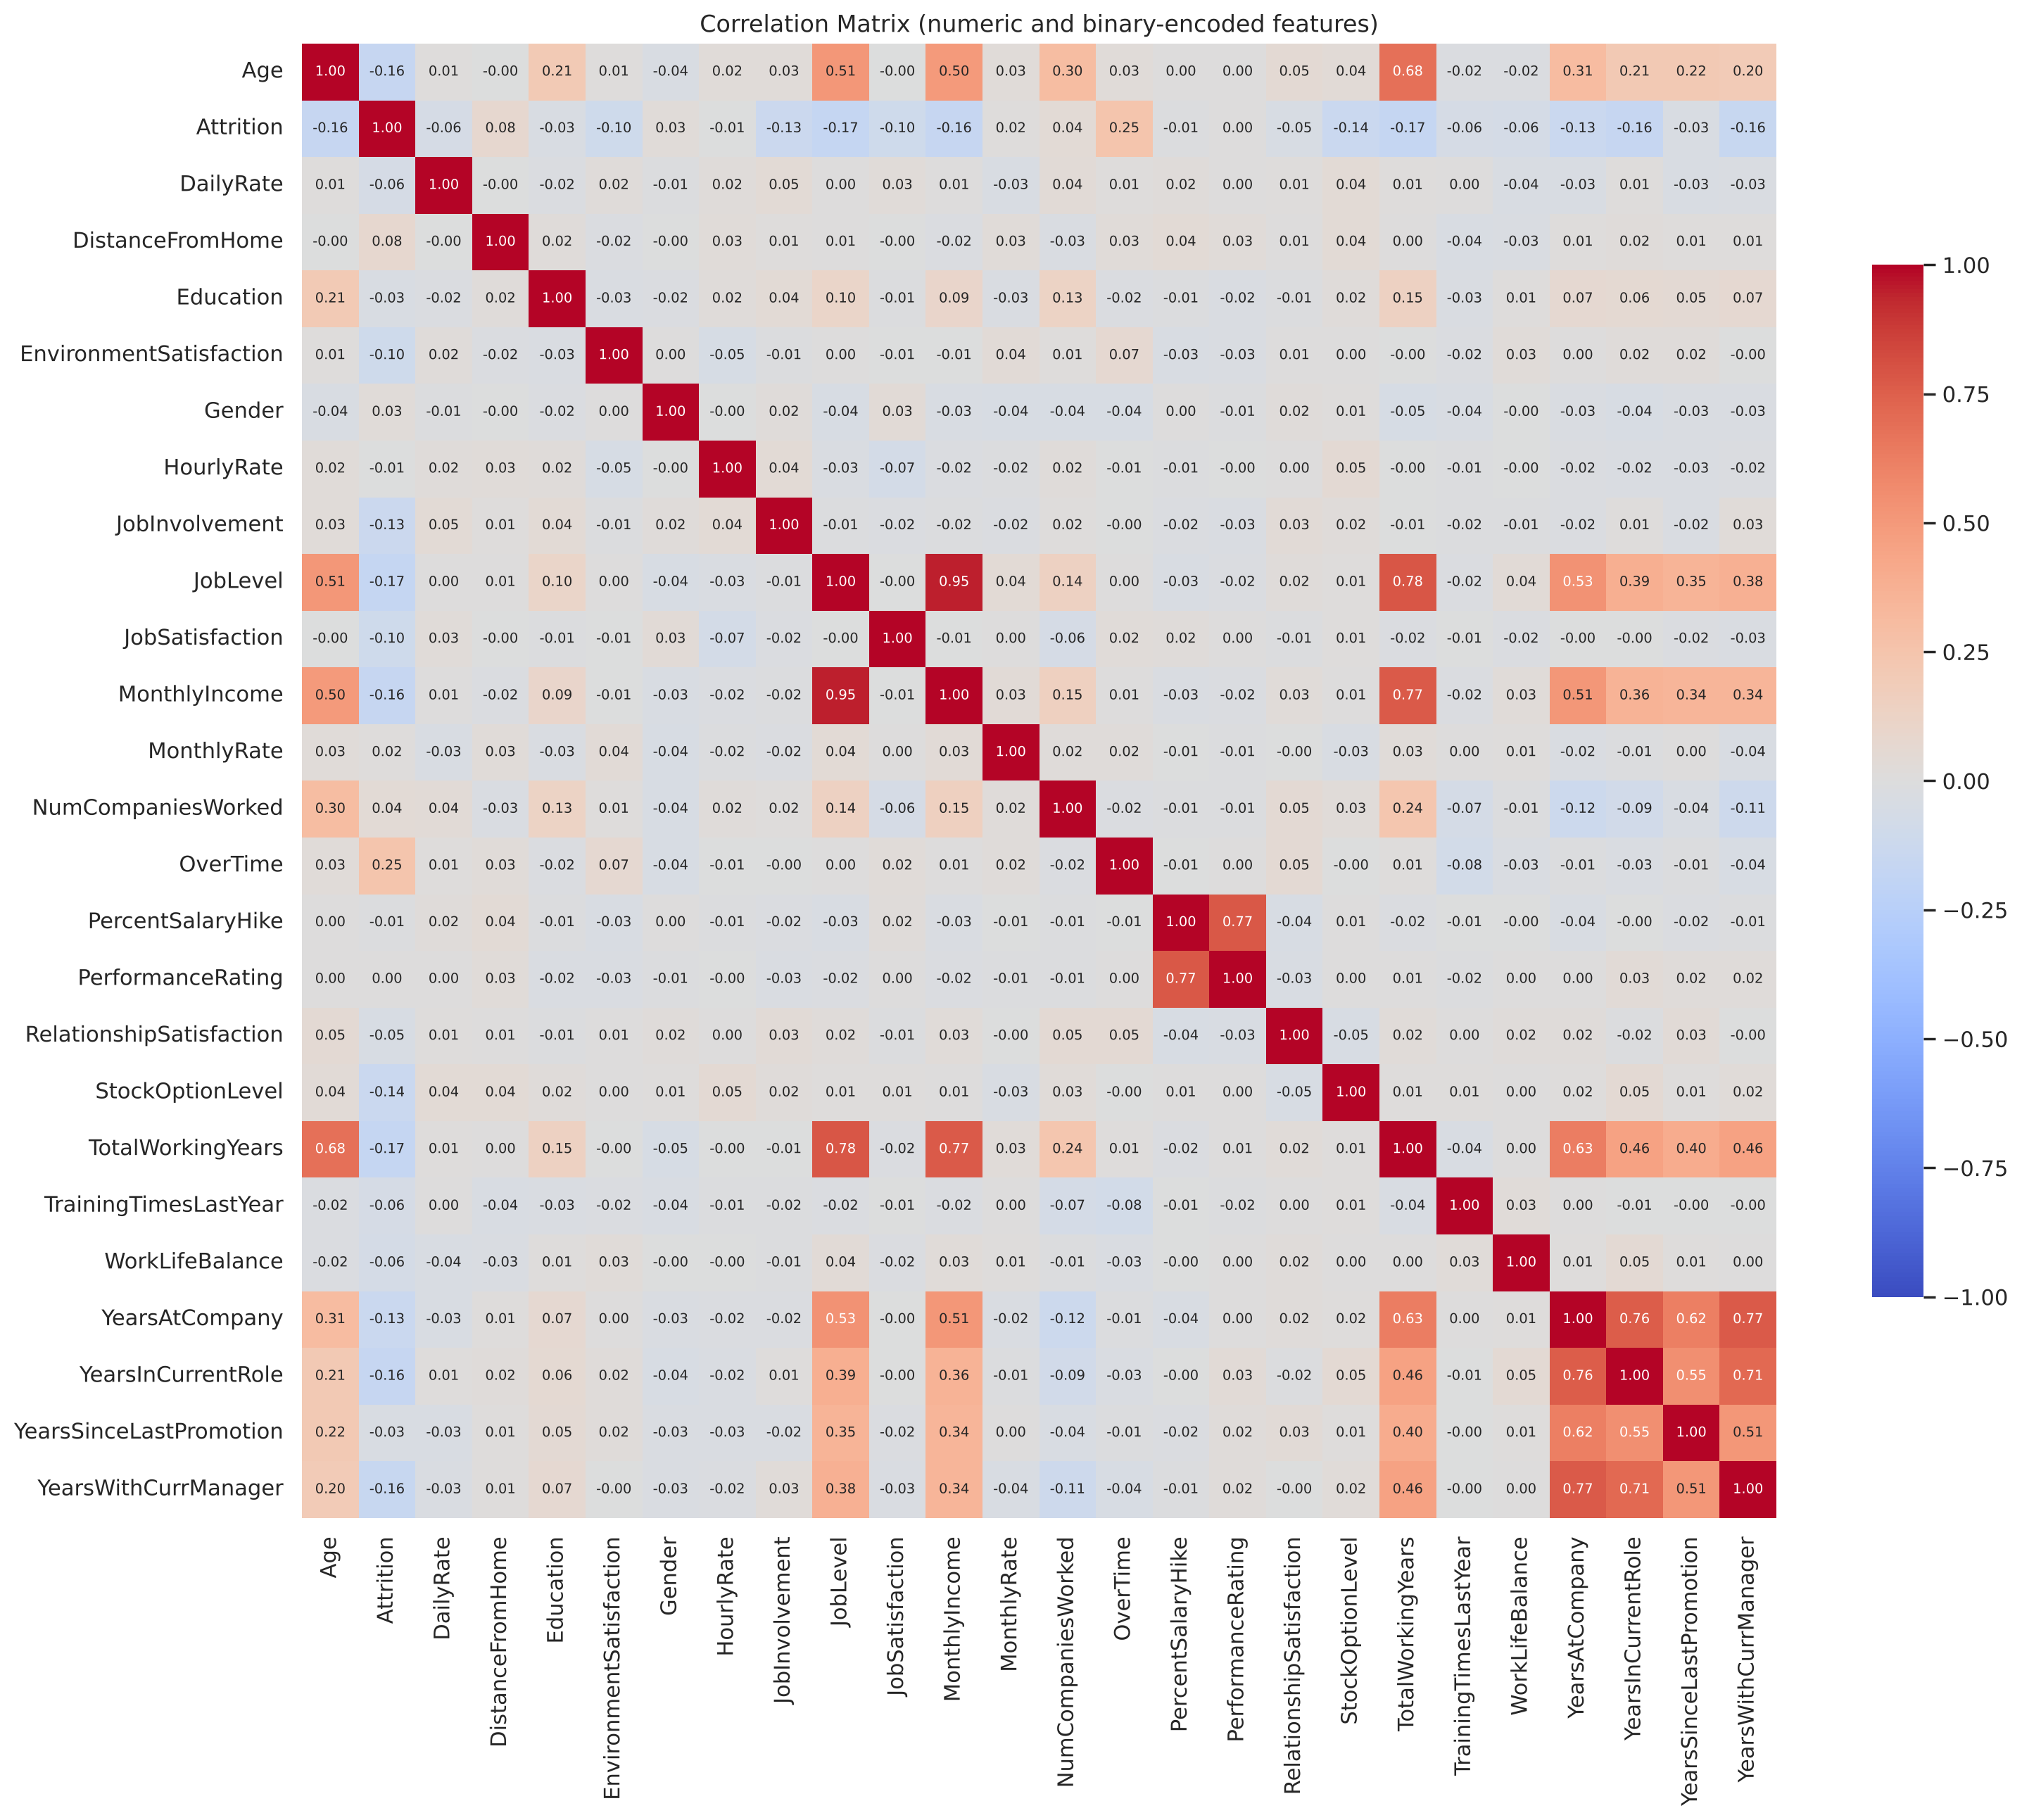

In [7]:
import seaborn as sns

corr_df = df.copy()

# Binary text columns -> 0/1 (Attrition first, so you can see what correlates with the target)
corr_df["Attrition"] = corr_df["Attrition"].map({"Yes": 1, "No": 0})
corr_df["OverTime"]  = corr_df["OverTime"].map({"Yes": 1, "No": 0})
corr_df["Gender"]    = corr_df["Gender"].map({"Male": 1, "Female": 0})

# Drop constant columns and the ID (constants have zero variance, so they'd show as NaN in the matrix)
corr_df = corr_df.drop(columns=["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"])

# Keep numeric columns only (this leaves out the multi-category text columns)
corr = corr_df.select_dtypes(include="number").corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True, cbar_kws={"shrink": 0.7})
plt.title("Correlation Matrix (numeric and binary-encoded features)")
plt.tight_layout()
plt.savefig("../docs/eda_correlation_matrix.png", dpi=150)
plt.show()

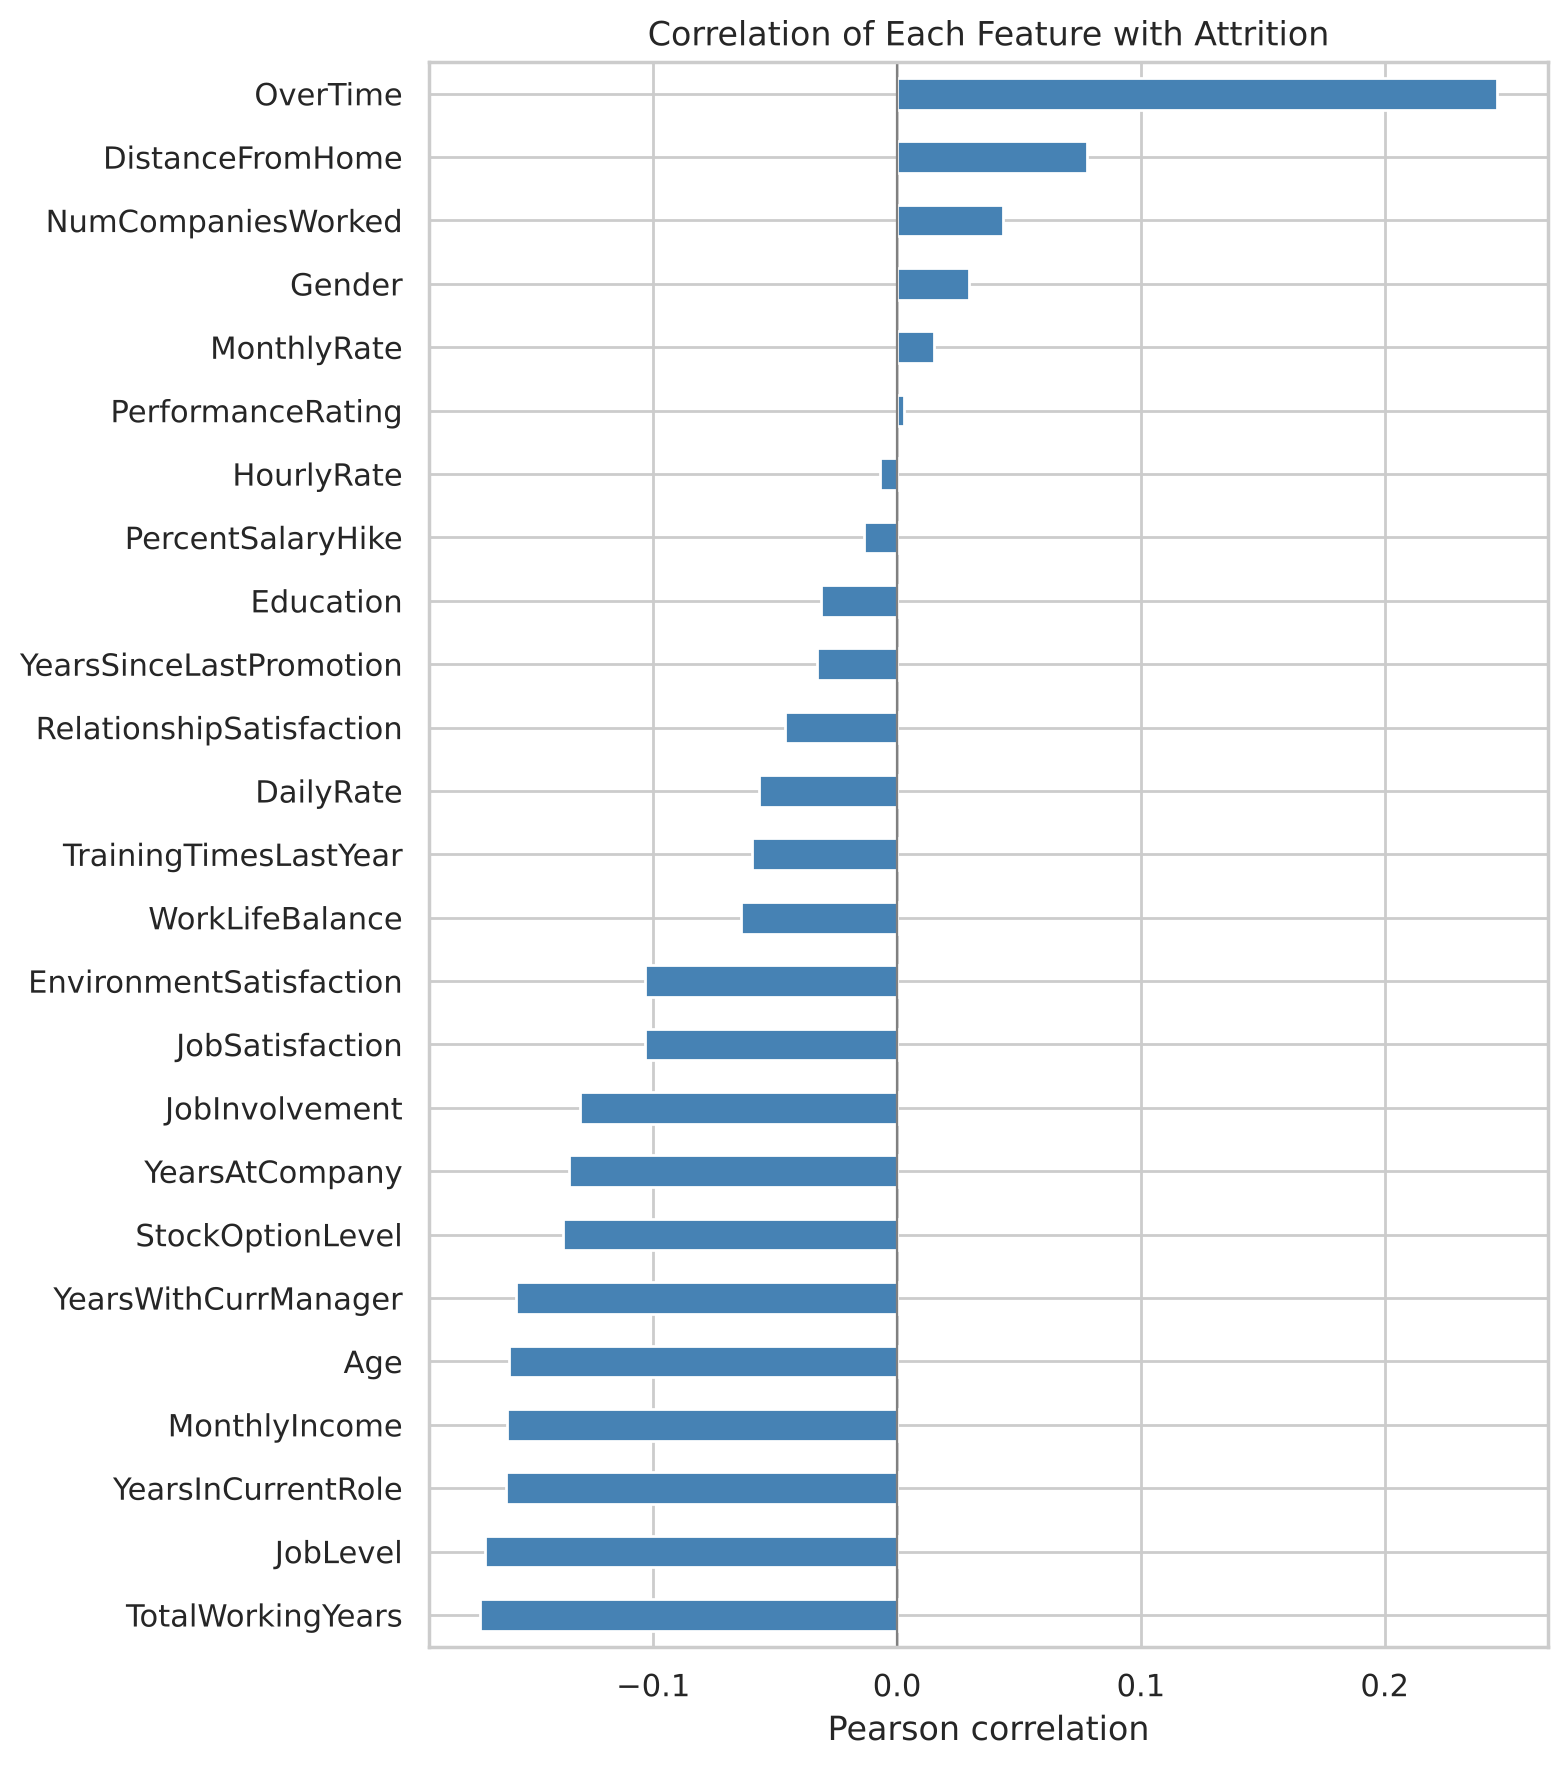

In [8]:
corr["Attrition"].drop("Attrition").sort_values().plot(
    kind="barh", figsize=(8, 9), color="steelblue", edgecolor="white")
plt.title("Correlation of Each Feature with Attrition")
plt.xlabel("Pearson correlation")
plt.axvline(0, color="grey", linewidth=0.8)
plt.tight_layout()
plt.savefig("../docs/eda_attrition_correlations.png", dpi=150)
plt.show()

In [9]:
ordinal_labels = {
    "Education": {1: "Below College", 2: "College", 3: "Bachelor", 4: "Master", 5: "Doctor"},
    "EnvironmentSatisfaction": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "JobInvolvement": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "JobSatisfaction": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "PerformanceRating": {1: "Low", 2: "Good", 3: "Excellent", 4: "Outstanding"},
    "RelationshipSatisfaction": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "WorkLifeBalance": {1: "Bad", 2: "Good", 3: "Better", 4: "Best"},
}

In [10]:
# Age bands match config/config.yaml (fairness.age_bins / fairness.age_labels)
age_bins   = [18, 30, 46, 65]
age_labels = ["<30", "30-45", ">45"]

df["AgeBand"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels, right=False)

print(df["AgeBand"].value_counts().sort_index())   # check group sizes

AgeBand
<30      326
30-45    871
>45      273
Name: count, dtype: int64


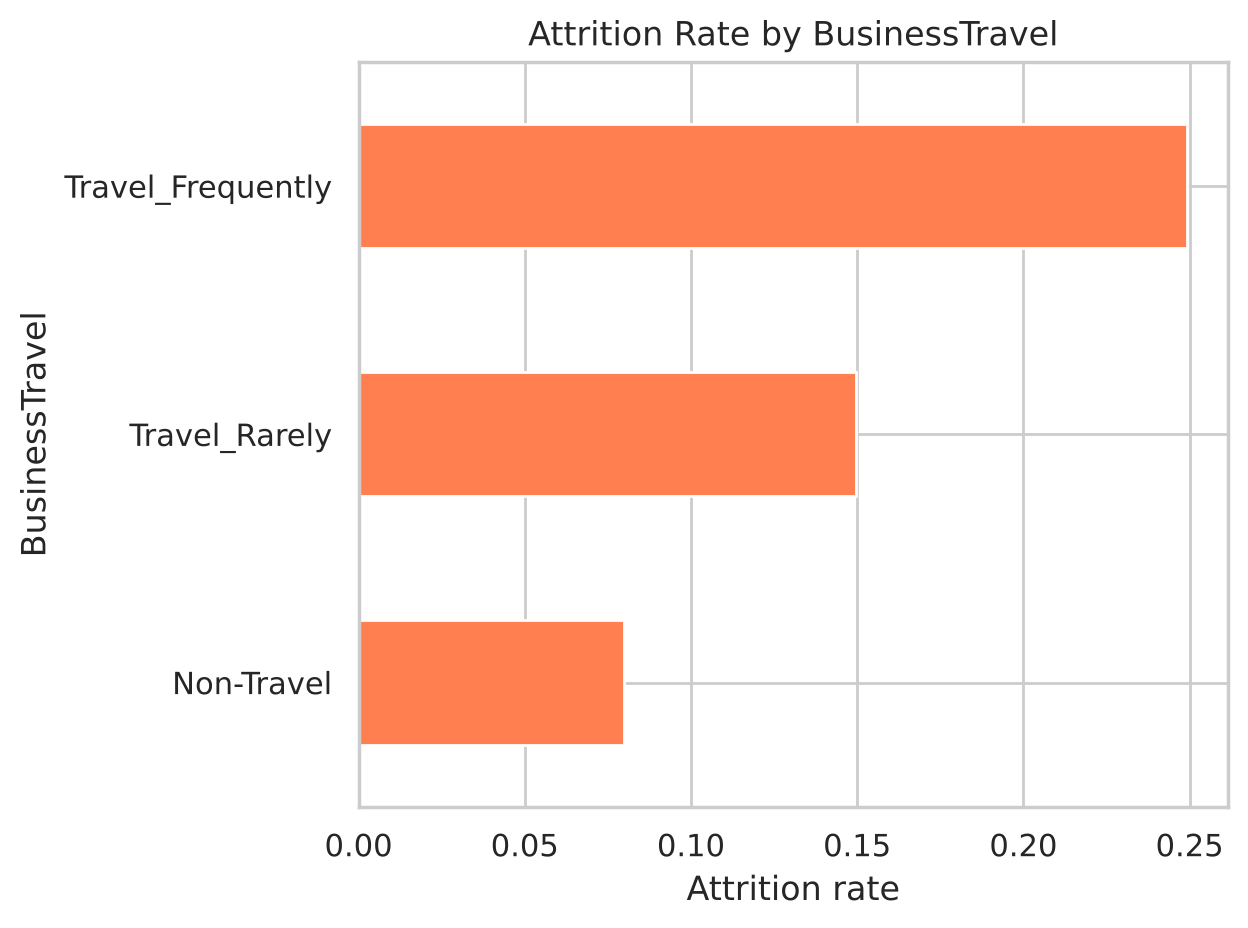

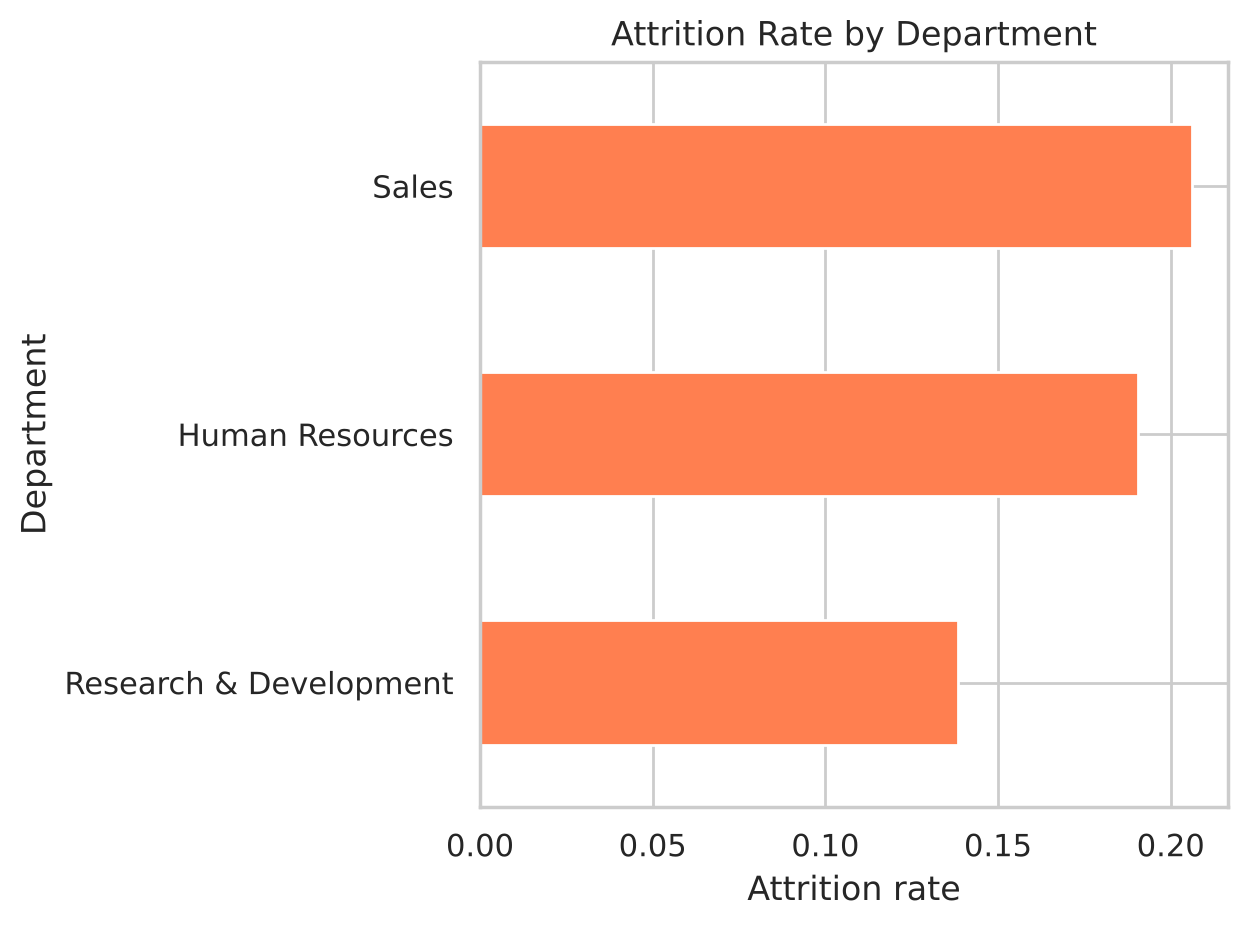

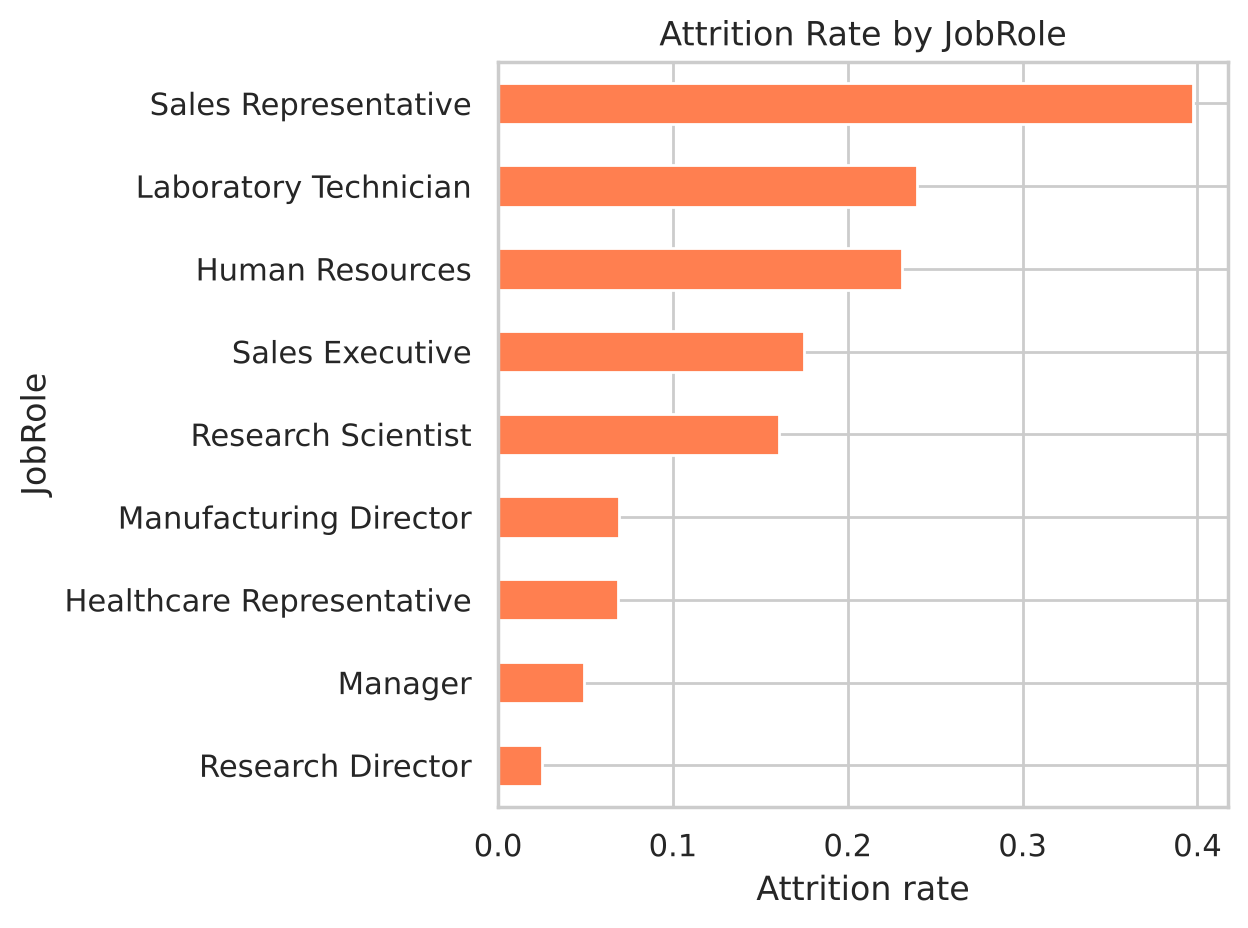

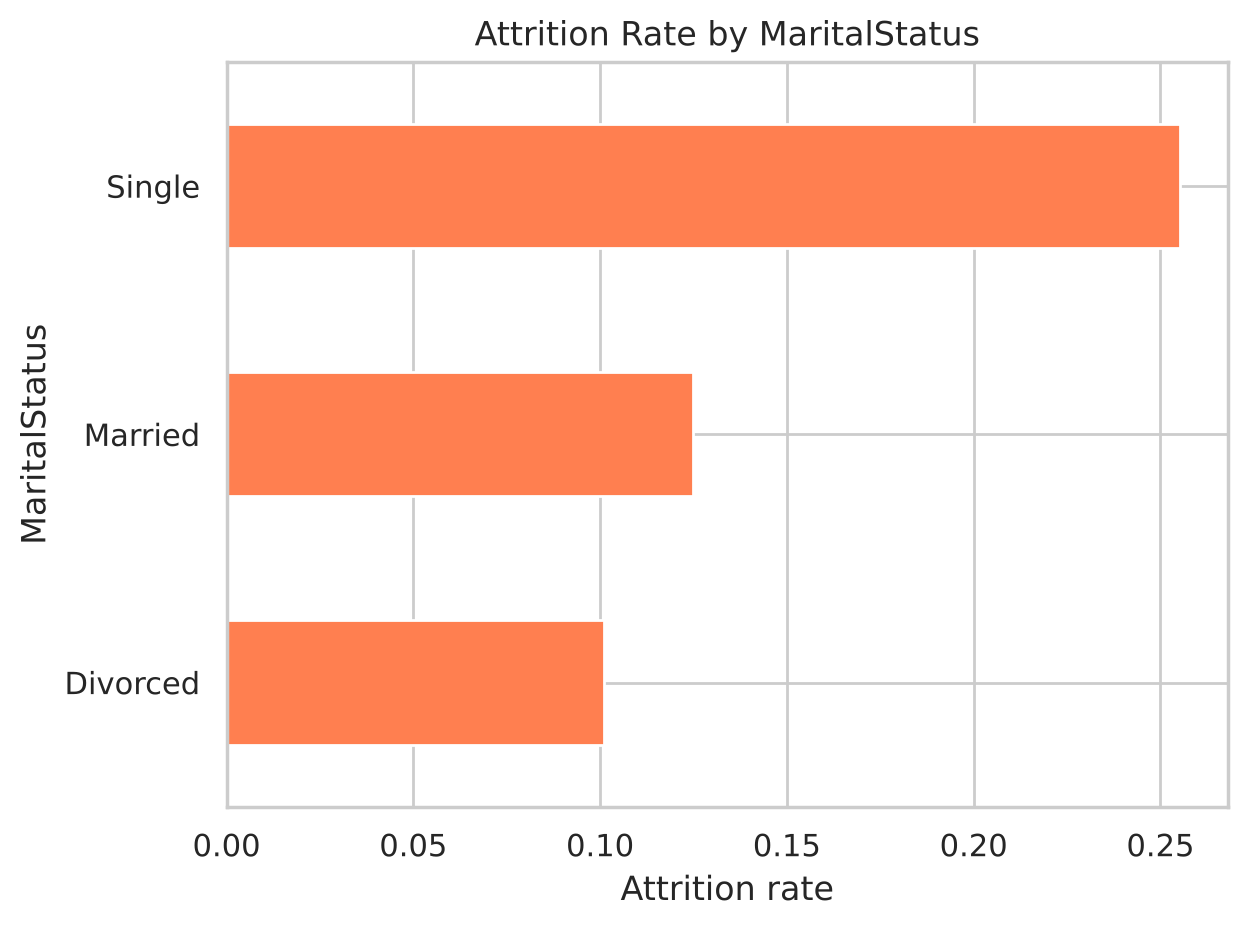

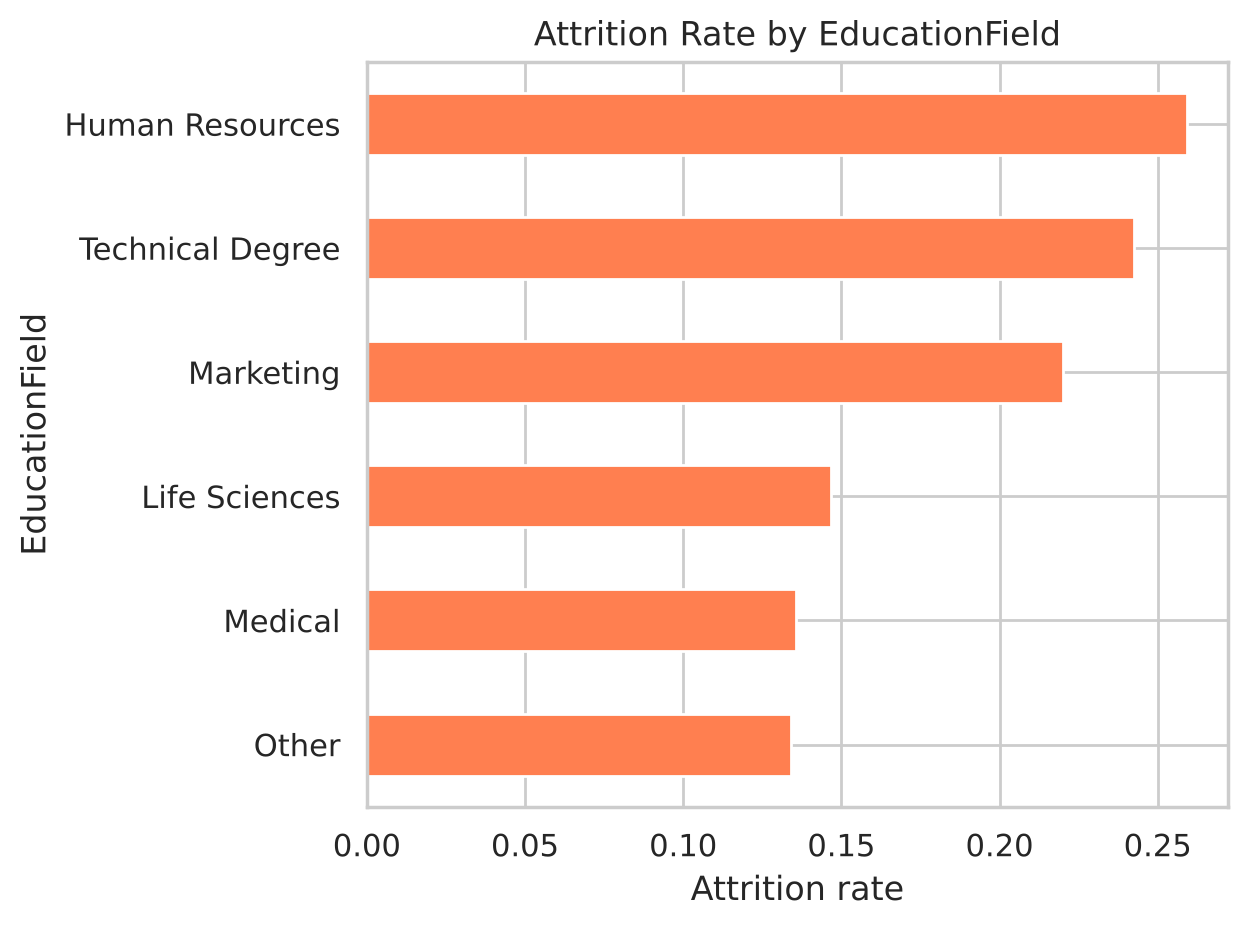

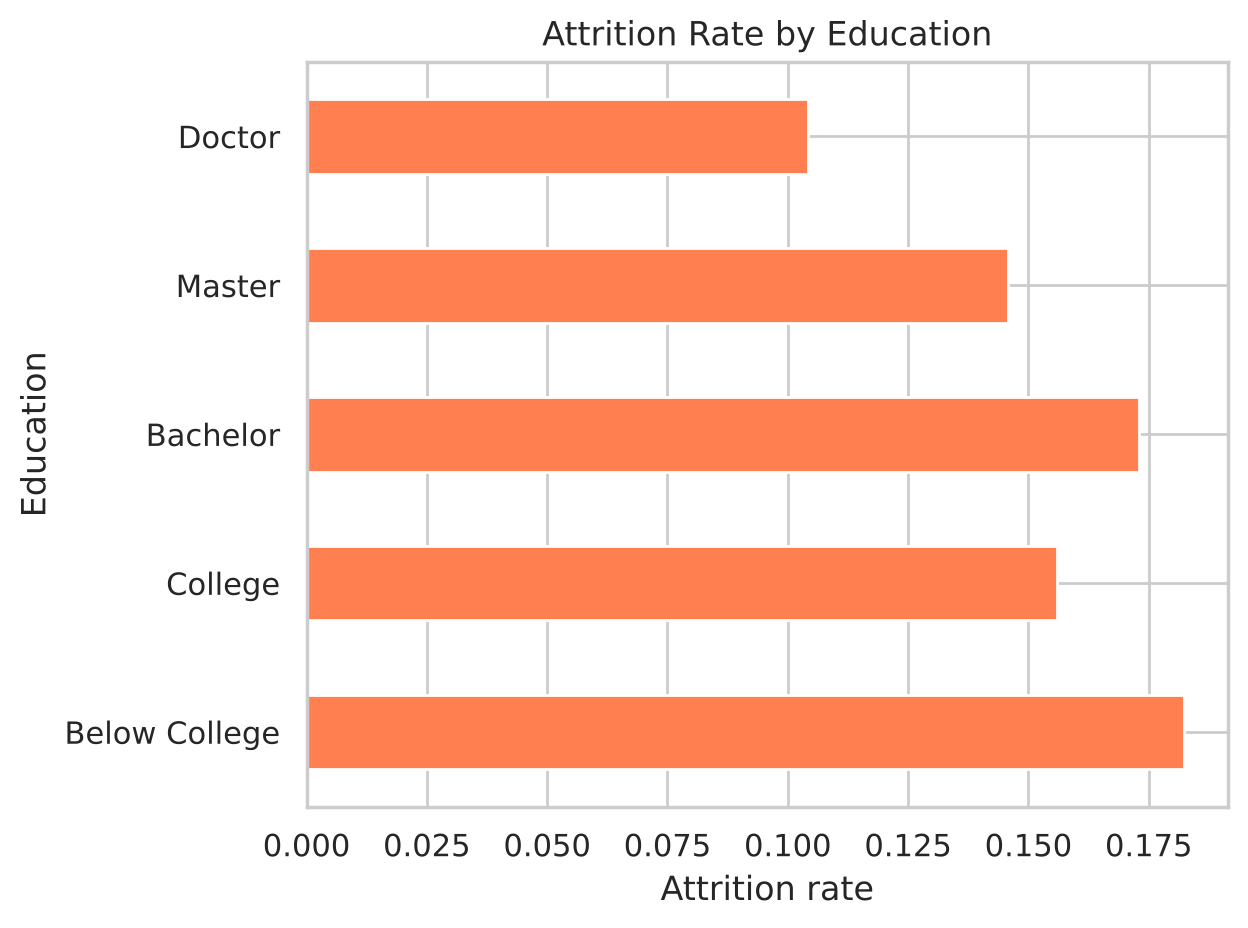

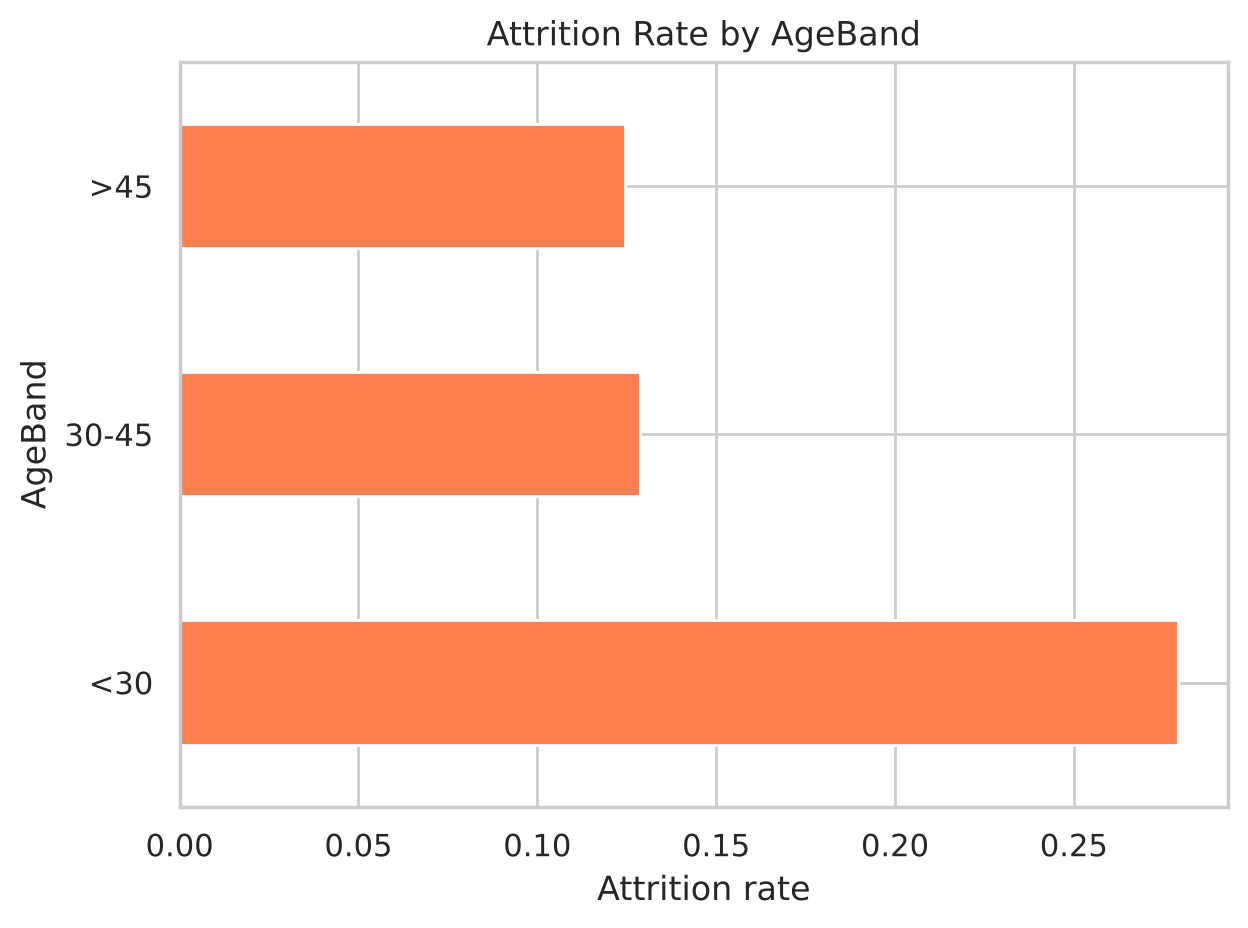

In [11]:
for col in ["BusinessTravel", "Department", "JobRole", "MaritalStatus", "EducationField", "Education", "AgeBand"]:
   rate = df.groupby(col, observed=True)["Attrition"].apply(lambda s: (s == "Yes").mean())

   if col == "Education":
        rate = rate.sort_index()
        rate.index = rate.index.map(ordinal_labels["Education"])
   elif col == "AgeBand":
        rate = rate.sort_index()
   else:
    rate = rate.sort_values()

   rate.plot(kind="barh", title=f"Attrition Rate by {col}", color="coral")
   plt.xlabel("Attrition rate")
   plt.tight_layout()
   plt.savefig(f"../docs/eda_attrition_by_{col}.png", dpi=150)
   plt.show()